In [1]:
import matplotlib.pyplot as plt
import numpy as np

import earthkit.hydro as ekh

network = ekh.river_network.load("efas", "5", use_cache=False)

Cache disabled.


# Catchment outlines

`catchments.find` answers "which cells drain to this point?" and returns a labelled field.
`catchments.outline` answers "where is the edge of that area?" and returns the boundary as
coordinate pairs, ready to plot or export.

We delineate two nested gauges on the Rhine: Basel, in the upper basin, and Lobith, at the
Dutch border.

In [2]:
gauges = {"Rhine at Basel": (47.5583, 7.5917), "Rhine at Lobith": (51.8417, 6.1083)}

## The catchment as a labelled field

Passing `overwrite=False` keeps both gauges as separate subcatchments, rather than letting
the downstream one absorb the upstream one. Each cell is labelled with the index of the
gauge it drains to.

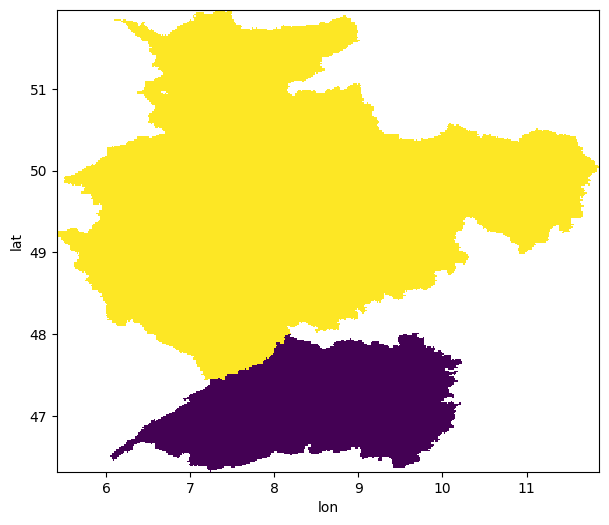

In [3]:
labels = ekh.catchments.find(network, locations=gauges, overwrite=False)

# Crop away the rest of the EFAS domain, which is not part of either catchment.
rhine = labels.where(labels.notnull(), drop=True)

rhine.plot(cmap="viridis", add_colorbar=False, figsize=(7, 6))
plt.show()

## The catchment as an outline

`catchments.outline` takes the same arguments. Because we passed a dict of named gauges, it
returns a dict keyed the same way, each value an array of `(latitude, longitude)` pairs
tracing that catchment along the edges of its gridcells.

In [4]:
outlines = ekh.catchments.outline(network, locations=gauges, overwrite=False)

for name, outline in outlines.items():
    print(f"{name}: {outline.shape[0]} points")

outlines["Rhine at Basel"][:4]

Rhine at Basel: 647 points
Rhine at Lobith: 1445 points


array([[48.01666667,  9.63333333],
       [48.01666667,  9.71666667],
       [48.        ,  9.71666667],
       [48.        ,  9.7       ]])

Only the corners at which the boundary turns are kept, so a 15,000-cell catchment comes back
as a few hundred points. The first point is repeated as the last, which closes the ring.

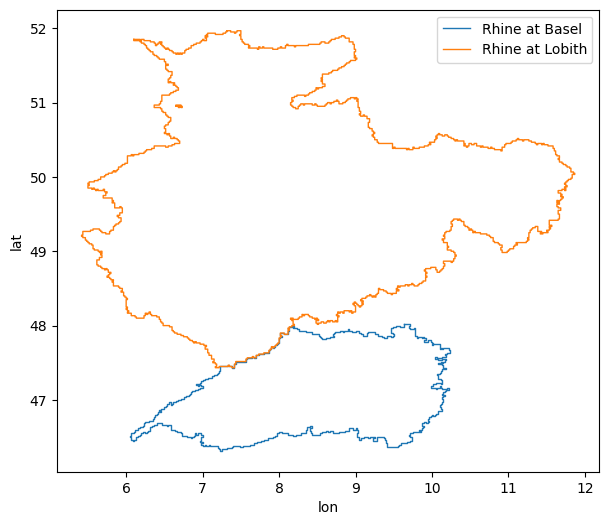

In [5]:
fig, ax = plt.subplots(figsize=(7, 6))

for name, outline in outlines.items():
    ax.plot(outline[:, 1], outline[:, 0], lw=1, label=name)

ax.set(xlabel="lon", ylabel="lat")
ax.legend()
plt.show()

## The two agree

The outline runs along cell edges rather than through cell centres, so it encloses exactly
the cells `find` labelled. Drawing one on top of the other shows the boundaries land on the
edge of the coloured area.

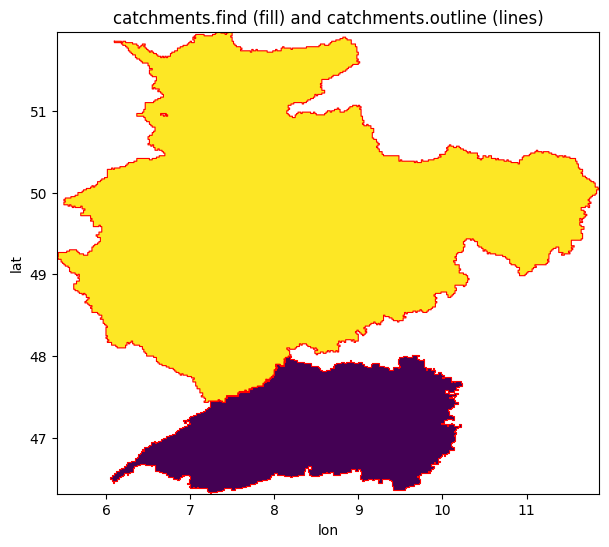

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))

rhine.plot(ax=ax, cmap="viridis", add_colorbar=False)
for name, outline in outlines.items():
    ax.plot(outline[:, 1], outline[:, 0], color="red", lw=0.8)

ax.set_title("catchments.find (fill) and catchments.outline (lines)")
plt.show()

## Catchments with more than one ring

A catchment does not always have a single boundary: it can enclose a hole, or parts of it may
touch only diagonally. Those cases come back as one array with a row of NaNs between
consecutive rings, largest ring first. Plotting libraries break the line at the NaNs, so the
rings above are drawn separately without a spurious segment joining them.

In [7]:
for name, outline in outlines.items():
    n_rings = 1 + np.isnan(outline[:, 0]).sum()
    print(f"{name}: {n_rings} ring(s)")

Rhine at Basel: 1 ring(s)
Rhine at Lobith: 3 ring(s)


## See also

- [Catchment delineation](../howto/delineate_catchments.rst) — how-to guide
- [Finding catchments](finding_catchments.ipynb) — the other ways to specify locations